In [1]:
from pathlib import Path
import pandas as pd

# Locate project root
ROOT = Path.cwd()

if ROOT.name.lower() in ["notebooks", "notebook"]:
    ROOT = ROOT.parent

EVENT_FILE = ROOT / "data" / "processed" / "ehr_event_log_clean.csv"
CASE_FILE = ROOT / "data" / "processed" / "ehr_cases_clean.csv"

assert EVENT_FILE.exists(), f"Missing: {EVENT_FILE}"
assert CASE_FILE.exists(), f"Missing: {CASE_FILE}"

events = pd.read_csv(EVENT_FILE)
cases = pd.read_csv(CASE_FILE)

events["timestamp"] = pd.to_datetime(events["timestamp"])

# Identify final activity of each case
last_events = (
    events.sort_values(
        ["case_id", "timestamp", "event_sequence"]
    )
    .groupby("case_id")
    .tail(1)
    [["case_id", "activity", "event_status"]]
    .rename(columns={
        "activity": "final_activity",
        "event_status": "final_event_status"
    })
)

# Compare case disposition with final event
conformance = cases[
    ["case_id", "disposition"]
].merge(
    last_events,
    on="case_id",
    how="left",
    validate="one_to_one"
)

# Summarize final activities by disposition
summary = pd.crosstab(
    conformance["disposition"],
    conformance["final_activity"],
    margins=True
)

display(summary)

# Isolate Left Before Completion cases
incomplete_cases = conformance[
    conformance["disposition"] == "Left Before Completion"
]

print("Total incomplete cases:", len(incomplete_cases))
print(
    "Incomplete cases ending in Discharge:",
    (incomplete_cases["final_activity"] == "Discharge").sum()
)

display(incomplete_cases.head(20))

final_activity,Discharge,All
disposition,,
Admitted,66,66
Discharged Home,380,380
Left Before Completion,16,16
Transferred,38,38
All,500,500


Total incomplete cases: 16
Incomplete cases ending in Discharge: 16


,case_id,disposition,final_activity,final_event_status
25,CF-0000026,Left Before Completion,Discharge,Completed
55,CF-0000056,Left Before Completion,Discharge,Completed
102,CF-0000103,Left Before Completion,Discharge,Completed
112,CF-0000113,Left Before Completion,Discharge,Completed
132,CF-0000133,Left Before Completion,Discharge,Delayed
208,CF-0000209,Left Before Completion,Discharge,Completed
220,CF-0000221,Left Before Completion,Discharge,Completed
298,CF-0000299,Left Before Completion,Discharge,Completed
307,CF-0000308,Left Before Completion,Discharge,Completed
340,CF-0000341,Left Before Completion,Discharge,Completed


# Activity sequence conformance analysis

In [2]:
# Week 4 - Activity Sequence Conformance Analysis

# 1. Build ordered activity sequence for every case
ordered_events = events.sort_values(
    ["case_id", "timestamp", "event_sequence"]
).copy()

case_sequences = (
    ordered_events.groupby("case_id")["activity"]
    .apply(lambda x: " → ".join(x.astype(str)))
    .reset_index(name="activity_sequence")
)

# 2. Attach disposition
sequence_analysis = cases[
    ["case_id", "disposition"]
].merge(
    case_sequences,
    on="case_id",
    how="left",
    validate="one_to_one"
)

# 3. Compare sequence lengths
sequence_analysis["activity_count"] = (
    sequence_analysis["activity_sequence"]
    .str.count(" → ") + 1
)

print("Average activity count by disposition:")
display(
    sequence_analysis.groupby("disposition")[
        "activity_count"
    ].agg(["count", "mean", "min", "max"])
    .round(2)
)

# 4. Most common activity sequences by disposition
for disposition in sequence_analysis["disposition"].unique():

    print(f"\n--- {disposition} ---")

    subset = sequence_analysis[
        sequence_analysis["disposition"] == disposition
    ]

    display(
        subset["activity_sequence"]
        .value_counts()
        .head(5)
        .rename_axis("Activity Sequence")
        .reset_index(name="Case Count")
    )

# 5. Inspect the final three activities of incomplete cases
incomplete_ids = set(
    cases.loc[
        cases["disposition"] == "Left Before Completion",
        "case_id"
    ]
)

print("\nFinal three activities of incomplete cases:")

display(
    ordered_events[
        ordered_events["case_id"].isin(incomplete_ids)
    ]
    .groupby("case_id")
    .tail(3)
    [["case_id", "activity", "event_status"]]
    .sort_values(["case_id", "activity"])
)

Average activity count by disposition:


,count,mean,min,max
disposition,,,,
Admitted,66,11.50,8,15
Discharged Home,380,9.53,6,14
Left Before Completion,16,8.88,6,12
Transferred,38,9.32,6,13



--- Discharged Home ---


,Activity Sequence,Case Count
0,Registration → Triage → Doctor Assessment → La...,128
1,Registration → Triage → Doctor Assessment → La...,80
2,Registration → Triage → Doctor Assessment → Tr...,46
3,Registration → Triage → Doctor Assessment → La...,23
4,Registration → Triage → Doctor Assessment → La...,22



--- Transferred ---


,Activity Sequence,Case Count
0,Registration → Triage → Doctor Assessment → La...,11
1,Registration → Triage → Doctor Assessment → La...,5
2,Registration → Triage → Doctor Assessment → Tr...,4
3,Registration → Triage → Doctor Assessment → Im...,4
4,Registration → Triage → Doctor Assessment → La...,3


... (2 outputs left out)


--- Left Before Completion ---


,Activity Sequence,Case Count
0,Registration → Triage → Doctor Assessment → La...,7
1,Registration → Triage → Doctor Assessment → La...,2
2,Registration → Triage → Doctor Assessment → Im...,2
3,Registration → Triage → Doctor Assessment → Tr...,2
4,Registration → Triage → Doctor Assessment → Im...,1



Final three activities of incomplete cases:


,case_id,activity,event_status
246,CF-0000026,Discharge,Completed
245,CF-0000026,Discharge Preparation,Completed
244,CF-0000026,Treatment,Delayed
527,CF-0000056,Discharge,Completed
526,CF-0000056,Discharge Preparation,Completed
525,CF-0000056,Doctor Assessment,Completed
1000,CF-0000103,Discharge,Completed
999,CF-0000103,Discharge Preparation,Reworked
998,CF-0000103,Doctor Assessment,Completed
1091,CF-0000113,Discharge,Completed


# Transition-level conformance analysis

In [6]:
# Week 4 - Fixed Transition-level Conformance Analysis

# 1. Sort events chronologically
ordered_events = events.sort_values(
    ["case_id", "timestamp", "event_sequence"]
).copy()

# 2. Calculate previous activity
ordered_events["previous_activity"] = (
    ordered_events.groupby("case_id")["activity"].shift(1)
)

# 3. Attach disposition from case table
transition_data = ordered_events.merge(
    cases[["case_id", "disposition"]],
    on="case_id",
    how="left",
    validate="many_to_one",
    suffixes=("_event", "")
)

# 4. Create transitions
transitions = transition_data.dropna(
    subset=["previous_activity"]
).copy()

transitions["transition"] = (
    transitions["previous_activity"].astype(str)
    + " → "
    + transitions["activity"].astype(str)
)

# 5. Filter target transition
target_transition = "Discharge Preparation → Discharge"

discharge_transition = transitions[
    transitions["transition"] == target_transition
].copy()

print("Discharge Preparation → Discharge by disposition:")

result = (
    discharge_transition.groupby("disposition")["case_id"]
    .nunique()
    .reindex(cases["disposition"].unique(), fill_value=0)
    .rename("case_count")
    .to_frame()
)

display(result)

# 6. Chronological final three events for incomplete cases
incomplete_ids = set(
    cases.loc[
        cases["disposition"] == "Left Before Completion",
        "case_id"
    ]
)

print("\nFinal three events of incomplete cases:")

display(
    ordered_events[
        ordered_events["case_id"].isin(incomplete_ids)
    ]
    .groupby("case_id")
    .tail(3)
    [["case_id", "timestamp", "activity", "event_status"]]
    .sort_values(["case_id", "timestamp"])
    .reset_index(drop=True)
)

# 7. Top 10 transitions by disposition
for disposition in cases["disposition"].dropna().unique():

    print(f"\nTop transitions: {disposition}")

    subset = transitions[
        transitions["disposition"] == disposition
    ]

    display(
        subset["transition"]
        .value_counts()
        .head(10)
        .rename_axis("Transition")
        .reset_index(name="Frequency")
    )

Discharge Preparation → Discharge by disposition:


,case_count
disposition,
Discharged Home,380
Transferred,38
Admitted,66
Left Before Completion,16



Final three events of incomplete cases:


,case_id,timestamp,activity,event_status
0,CF-0000026,2026-06-04 13:33:14,Treatment,Delayed
1,CF-0000026,2026-06-04 13:55:14,Discharge Preparation,Completed
2,CF-0000026,2026-06-04 13:59:14,Discharge,Completed
3,CF-0000056,2026-05-02 10:57:49,Doctor Assessment,Completed
4,CF-0000056,2026-05-02 11:47:49,Discharge Preparation,Completed
5,CF-0000056,2026-05-02 12:07:49,Discharge,Completed
6,CF-0000103,2026-06-03 19:57:27,Doctor Assessment,Completed
7,CF-0000103,2026-06-03 20:10:27,Discharge Preparation,Reworked
8,CF-0000103,2026-06-03 20:28:27,Discharge,Completed
9,CF-0000113,2026-05-24 08:58:17,Treatment,Completed



Top transitions: Discharged Home


,Transition,Frequency
0,Triage → Doctor Assessment,389
1,Registration → Triage,380
2,Discharge Preparation → Discharge,380
3,Doctor Assessment → Lab Order,293
4,Lab Order → Lab Sample Collection,293
5,Lab Sample Collection → Lab Result,293
6,Treatment → Discharge Preparation,273
7,Lab Result → Treatment,179
8,Imaging Order → Imaging,142
9,Imaging → Treatment,142


... (2 outputs left out)


Top transitions: Admitted


,Transition,Frequency
0,Registration → Triage,66
1,Triage → Doctor Assessment,66
2,Admission Decision → Bed Assignment,66
3,Bed Assignment → Discharge Preparation,66
4,Discharge Preparation → Discharge,66
5,Treatment → Admission Decision,47
6,Doctor Assessment → Lab Order,46
7,Lab Order → Lab Sample Collection,46
8,Lab Sample Collection → Lab Result,46
9,Imaging Order → Imaging,32



Top transitions: Left Before Completion


,Transition,Frequency
0,Registration → Triage,16
1,Triage → Doctor Assessment,16
2,Discharge Preparation → Discharge,16
3,Treatment → Discharge Preparation,12
4,Doctor Assessment → Lab Order,10
5,Lab Order → Lab Sample Collection,10
6,Lab Sample Collection → Lab Result,10
7,Lab Result → Treatment,7
8,Imaging Order → Imaging,6
9,Imaging → Treatment,6


In [7]:
pd.set_option("display.max_colwidth", None)

print("Full activity sequences for incomplete cases:")

display(
    sequence_analysis[
        sequence_analysis["disposition"] == "Left Before Completion"
    ][
        ["case_id", "activity_count", "activity_sequence"]
    ].to_string(index=False)
)

Full activity sequences for incomplete cases:


'   case_id  activity_count                                                                                                                                                                        activity_sequence\nCF-0000026               9                                               Registration → Triage → Doctor Assessment → Lab Order → Lab Sample Collection → Lab Result → Treatment → Discharge Preparation → Discharge\nCF-0000056              12 Registration → Triage → Doctor Assessment → Lab Order → Lab Sample Collection → Lab Result → Imaging Order → Imaging → Treatment → Doctor Assessment → Discharge Preparation → Discharge\nCF-0000103               9                                                  Registration → Triage → Doctor Assessment → Imaging Order → Imaging → Treatment → Doctor Assessment → Discharge Preparation → Discharge\nCF-0000113               8                                                                      Registration → Triage → Doctor Assessment → Imaging

# Outcome deviation report

In [8]:
# Week 4 - Outcome Deviation Report

# A. Final event status by disposition
final_status_report = (
    conformance.groupby(
        ["disposition", "final_event_status"]
    )
    .size()
    .unstack(fill_value=0)
)

print("1. Final event status by disposition")
display(final_status_report)

# B. Final activity by disposition
final_activity_report = (
    conformance.groupby(
        ["disposition", "final_activity"]
    )
    .size()
    .unstack(fill_value=0)
)

print("\n2. Final activity by disposition")
display(final_activity_report)

# C. Repeated activities within cases
activity_counts = (
    ordered_events.groupby(["case_id", "activity"])
    .size()
    .reset_index(name="occurrences")
)

repeated_activities = activity_counts[
    activity_counts["occurrences"] > 1
].copy()

repeated_case_summary = (
    repeated_activities.groupby("case_id")
    .agg(
        repeated_activity_types=("activity", "nunique"),
        extra_occurrences=("occurrences", lambda x: (x - 1).sum())
    )
    .reset_index()
    .merge(
        cases[["case_id", "disposition"]],
        on="case_id",
        how="left"
    )
)

print("\n3. Cases with repeated activities by disposition")

display(
    repeated_case_summary.groupby("disposition")
    .agg(
        cases_with_repeats=("case_id", "nunique"),
        avg_repeated_activity_types=("repeated_activity_types", "mean"),
        total_extra_occurrences=("extra_occurrences", "sum")
    )
    .round(2)
)

# D. Incomplete case transition summary
incomplete_transitions = transitions[
    transitions["disposition"] == "Left Before Completion"
]

print("\n4. Incomplete case transition frequencies")

display(
    incomplete_transitions["transition"]
    .value_counts()
    .rename_axis("Transition")
    .reset_index(name="Frequency")
)

# E. Summary of confirmed observations
print("\n5. Conformance observations")
print("Total cases:", cases["case_id"].nunique())
print(
    "Incomplete cases:",
    (cases["disposition"] == "Left Before Completion").sum()
)
print(
    "Incomplete cases ending in Discharge:",
    len(incomplete_cases)
)
print(
    "Incomplete cases with Discharge Preparation -> Discharge:",
    discharge_transition[
        discharge_transition["disposition"] == "Left Before Completion"
    ]["case_id"].nunique()
)
print(
    "Cases with repeated activities:",
    repeated_case_summary["case_id"].nunique()
)

1. Final event status by disposition


final_event_status,Completed,Delayed,Reworked
disposition,,,
Admitted,53,11,2
Discharged Home,337,29,14
Left Before Completion,13,2,1
Transferred,31,5,2



2. Final activity by disposition


final_activity,Discharge
disposition,
Admitted,66
Discharged Home,380
Left Before Completion,16
Transferred,38



3. Cases with repeated activities by disposition


,cases_with_repeats,avg_repeated_activity_types,total_extra_occurrences
disposition,,,
Admitted,19,1.00,19
Discharged Home,107,1.08,116
Left Before Completion,4,1.00,4
Transferred,14,1.00,14



4. Incomplete case transition frequencies


,Transition,Frequency
0,Registration → Triage,16
1,Triage → Doctor Assessment,16
2,Discharge Preparation → Discharge,16
3,Treatment → Discharge Preparation,12
4,Doctor Assessment → Lab Order,10
5,Lab Order → Lab Sample Collection,10
6,Lab Sample Collection → Lab Result,10
7,Lab Result → Treatment,7
8,Imaging Order → Imaging,6
9,Imaging → Treatment,6



5. Conformance observations
Total cases: 500
Incomplete cases: 16
Incomplete cases ending in Discharge: 16
Incomplete cases with Discharge Preparation -> Discharge: 16
Cases with repeated activities: 144


# Formal conformance rule checks

In [9]:
# Week 4 - Provisional Conformance Rule Engine

# 1. Build case-level activity sets
case_activity_sets = (
    ordered_events.groupby("case_id")["activity"]
    .apply(set)
)

# 2. Build case-level activity presence table
case_checks = cases[["case_id", "disposition"]].copy()

case_checks["has_discharge_preparation"] = (
    case_checks["case_id"].map(
        lambda x: "Discharge Preparation" in case_activity_sets[x]
    )
)

case_checks["has_discharge"] = (
    case_checks["case_id"].map(
        lambda x: "Discharge" in case_activity_sets[x]
    )
)

case_checks["has_admission_decision"] = (
    case_checks["case_id"].map(
        lambda x: "Admission Decision" in case_activity_sets[x]
    )
)

case_checks["has_bed_assignment"] = (
    case_checks["case_id"].map(
        lambda x: "Bed Assignment" in case_activity_sets[x]
    )
)

# 3. Apply provisional rules

# Rule 1: Left Before Completion should not contain discharge activities.
case_checks["rule_1_violation"] = (
    (case_checks["disposition"] == "Left Before Completion")
    & (
        case_checks["has_discharge"]
        | case_checks["has_discharge_preparation"]
    )
)

# Rule 2: Admitted cases should contain admission decision and bed assignment.
case_checks["rule_2_violation"] = (
    (case_checks["disposition"] == "Admitted")
    & (
        ~case_checks["has_admission_decision"]
        | ~case_checks["has_bed_assignment"]
    )
)

# 4. Summarize rule results
rule_summary = pd.DataFrame({
    "Rule": [
        "Incomplete cases should not contain discharge activities",
        "Admitted cases should contain admission decision and bed assignment"
    ],
    "Violations": [
        case_checks["rule_1_violation"].sum(),
        case_checks["rule_2_violation"].sum()
    ],
    "Cases_Checked": [
        (case_checks["disposition"] == "Left Before Completion").sum(),
        (case_checks["disposition"] == "Admitted").sum()
    ]
})

rule_summary["Violation_Rate_Percent"] = (
    rule_summary["Violations"]
    / rule_summary["Cases_Checked"] * 100
).round(2)

display(rule_summary)

# 5. Extract violating cases
violations = case_checks[
    case_checks["rule_1_violation"]
    | case_checks["rule_2_violation"]
].copy()

print("Total violating cases:", len(violations))
display(violations)

,Rule,Violations,Cases_Checked,Violation_Rate_Percent
0,Incomplete cases should not contain discharge activities,16,16,100.0
1,Admitted cases should contain admission decision and bed assignment,0,66,0.0


Total violating cases: 16


,case_id,disposition,has_discharge_preparation,has_discharge,has_admission_decision,has_bed_assignment,rule_1_violation,rule_2_violation
25,CF-0000026,Left Before Completion,True,True,False,False,True,False
55,CF-0000056,Left Before Completion,True,True,False,False,True,False
102,CF-0000103,Left Before Completion,True,True,False,False,True,False
112,CF-0000113,Left Before Completion,True,True,False,False,True,False
132,CF-0000133,Left Before Completion,True,True,False,False,True,False
208,CF-0000209,Left Before Completion,True,True,False,False,True,False
220,CF-0000221,Left Before Completion,True,True,False,False,True,False
298,CF-0000299,Left Before Completion,True,True,False,False,True,False
307,CF-0000308,Left Before Completion,True,True,False,False,True,False
340,CF-0000341,Left Before Completion,True,True,False,False,True,False


# check transfer pathway

In [10]:
# Week 4 - Transfer Pathway Validation

transfer_cases = cases[
    cases["disposition"] == "Transferred"
]["case_id"]

transfer_events = ordered_events[
    ordered_events["case_id"].isin(transfer_cases)
]

print("Transferred cases:", transfer_cases.nunique())

print("\nActivities found in transferred cases:")
display(
    transfer_events["activity"]
    .value_counts()
    .to_frame("event_count")
)

# Check whether an explicit transfer activity exists
transfer_keywords = ["Transfer", "Transferred", "Transfer Out"]

activity_names = set(events["activity"].dropna().unique())

matching_activities = [
    activity for activity in activity_names
    if any(keyword.lower() in activity.lower()
           for keyword in transfer_keywords)
]

print("\nExplicit transfer activities:", matching_activities)

# Final activity distribution
print("\nFinal activity of transferred cases:")
display(
    transfer_events.groupby("case_id")
    .tail(1)["activity"]
    .value_counts()
)

Transferred cases: 38

Activities found in transferred cases:


,event_count
activity,
Triage,46
Doctor Assessment,44
Registration,38
Treatment,38
Discharge Preparation,38
Discharge,38
Lab Order,24
Lab Sample Collection,24
Lab Result,24



Explicit transfer activities: []

Final activity of transferred cases:


activity
Discharge    38
Name: count, dtype: int64

# Transfer pathway

In [11]:
# Week 4 - Transfer Conformance Rule

# Identify transfer-related activity names
transfer_keywords = ["transfer", "transferred"]

transfer_activities = [
    activity
    for activity in events["activity"].dropna().unique()
    if any(
        keyword in activity.lower()
        for keyword in transfer_keywords
    )
]

# Build case-level transfer activity check
case_checks["has_transfer_activity"] = (
    case_checks["case_id"].map(
        lambda case_id: any(
            activity in transfer_activities
            for activity in case_activity_sets[case_id]
        )
    )
)

# Apply provisional Rule 3
case_checks["rule_3_violation"] = (
    (case_checks["disposition"] == "Transferred")
    & (~case_checks["has_transfer_activity"])
)

# Combined rule summary
rule_3_summary = pd.DataFrame({
    "Rule": [
        "Transferred cases should contain an explicit transfer activity"
    ],
    "Violations": [
        case_checks["rule_3_violation"].sum()
    ],
    "Cases_Checked": [
        (case_checks["disposition"] == "Transferred").sum()
    ]
})

rule_3_summary["Violation_Rate_Percent"] = (
    rule_3_summary["Violations"]
    / rule_3_summary["Cases_Checked"] * 100
).round(2)

display(rule_3_summary)

# Show affected cases
display(
    case_checks.loc[
        case_checks["rule_3_violation"],
        ["case_id", "disposition", "has_transfer_activity"]
    ]
)

,Rule,Violations,Cases_Checked,Violation_Rate_Percent
0,Transferred cases should contain an explicit transfer activity,38,38,100.0


,case_id,disposition,has_transfer_activity
3,CF-0000004,Transferred,False
4,CF-0000005,Transferred,False
5,CF-0000006,Transferred,False
12,CF-0000013,Transferred,False
31,CF-0000032,Transferred,False
35,CF-0000036,Transferred,False
43,CF-0000044,Transferred,False
51,CF-0000052,Transferred,False
121,CF-0000122,Transferred,False
126,CF-0000127,Transferred,False


In [12]:
# Week 4 - Consolidated Conformance Report

import json
from pathlib import Path
from datetime import datetime

# 1. Define report rules
rules = [
    {
        "rule_id": "CF-R01",
        "rule": "Incomplete cases should not contain discharge activities",
        "disposition": "Left Before Completion",
        "violation_column": "rule_1_violation"
    },
    {
        "rule_id": "CF-R02",
        "rule": "Admitted cases should contain admission decision and bed assignment",
        "disposition": "Admitted",
        "violation_column": "rule_2_violation"
    },
    {
        "rule_id": "CF-R03",
        "rule": "Transferred cases should contain an explicit transfer activity",
        "disposition": "Transferred",
        "violation_column": "rule_3_violation"
    }
]

# 2. Build consolidated summary
report_rows = []

for rule in rules:
    subset = case_checks[
        case_checks["disposition"] == rule["disposition"]
    ]

    checked = len(subset)
    violations = int(subset[rule["violation_column"]].sum())

    report_rows.append({
        "rule_id": rule["rule_id"],
        "rule": rule["rule"],
        "cases_checked": checked,
        "violations": violations,
        "compliant_cases": checked - violations,
        "violation_rate_percent": round(
            violations / checked * 100, 2
        ) if checked else 0,
        "classification": "Provisional analytical rule"
    })

conformance_report = pd.DataFrame(report_rows)

display(conformance_report)

# 3. Prepare output directory
REPORT_DIR = ROOT / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# 4. Save CSV
csv_path = REPORT_DIR / "week4_conformance_report.csv"
conformance_report.to_csv(csv_path, index=False)

# 5. Save JSON
json_path = REPORT_DIR / "week4_conformance_report.json"

report_json = {
    "project": "CareFlow - Clinical Pathway Process Mining",
    "analysis": "Week 4 Conformance Analysis",
    "total_cases": int(cases["case_id"].nunique()),
    "total_events": int(len(events)),
    "generated_at": datetime.now().isoformat(timespec="seconds"),
    "rules": report_rows,
    "interpretation": (
        "Rule violations represent deviations from provisional "
        "analytical assumptions, not confirmed clinical violations."
    )
}

with open(json_path, "w", encoding="utf-8") as f:
    json.dump(report_json, f, indent=4)

print("Reports generated successfully:")
print(csv_path)
print(json_path)

,rule_id,rule,cases_checked,violations,compliant_cases,violation_rate_percent,classification
0,CF-R01,Incomplete cases should not contain discharge activities,16,16,0,100.0,Provisional analytical rule
1,CF-R02,Admitted cases should contain admission decision and bed assignment,66,0,66,0.0,Provisional analytical rule
2,CF-R03,Transferred cases should contain an explicit transfer activity,38,38,0,100.0,Provisional analytical rule


Reports generated successfully:
C:\Users\visha\Desktop\CareFlow-Clinical-Pathway-Process-Mining\reports\week4_conformance_report.csv
C:\Users\visha\Desktop\CareFlow-Clinical-Pathway-Process-Mining\reports\week4_conformance_report.json


# TO-BE process map generate

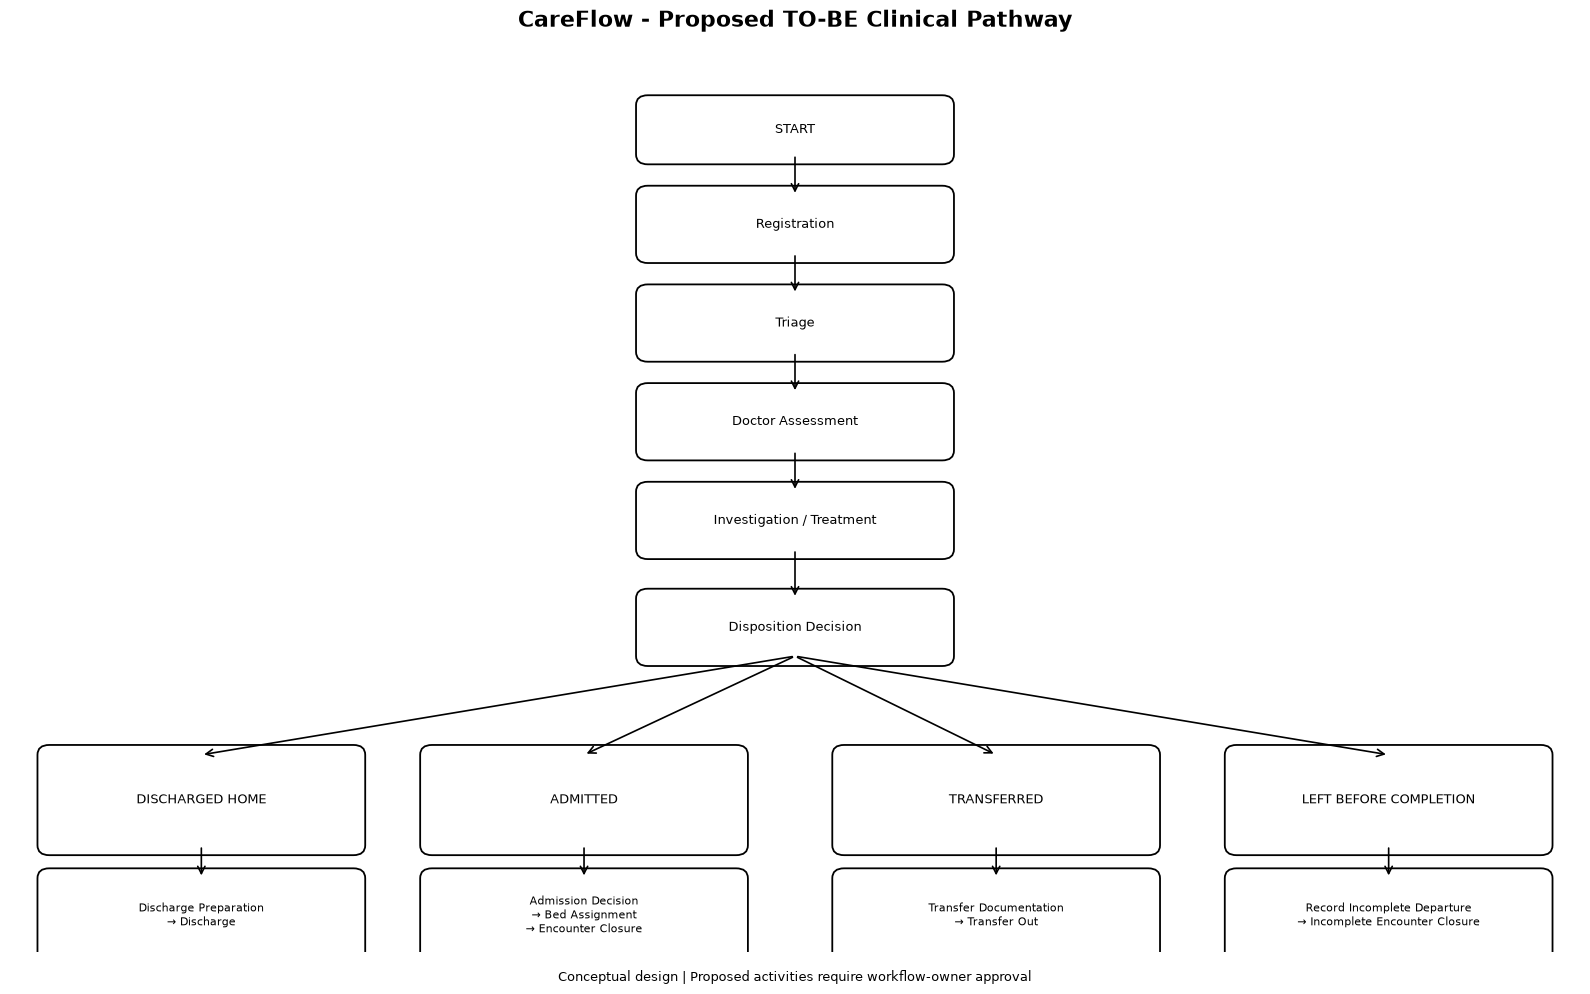

TO-BE process map saved: C:\Users\visha\Desktop\CareFlow-Clinical-Pathway-Process-Mining\outputs\careflow_to_be_process_map.png


In [13]:
# Week 4 - TO-BE Clinical Pathway Process Map

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from pathlib import Path

OUTPUT_DIR = ROOT / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(16, 10))
ax.set_xlim(0, 16)
ax.set_ylim(0, 11)
ax.axis("off")

def add_box(x, y, width, height, text, fontsize=9):
    box = FancyBboxPatch(
        (x, y), width, height,
        boxstyle="round,pad=0.12",
        linewidth=1.3,
        edgecolor="black",
        facecolor="white"
    )
    ax.add_patch(box)
    ax.text(
        x + width / 2,
        y + height / 2,
        text,
        ha="center",
        va="center",
        fontsize=fontsize,
        wrap=True
    )

def add_arrow(x1, y1, x2, y2, label=None):
    arrow = FancyArrowPatch(
        (x1, y1), (x2, y2),
        arrowstyle="->",
        mutation_scale=13,
        linewidth=1.2,
        color="black"
    )
    ax.add_patch(arrow)

    if label:
        ax.text(
            (x1 + x2) / 2,
            (y1 + y2) / 2 + 0.15,
            label,
            ha="center",
            fontsize=8
        )

# Start and common pathway
add_box(6.5, 9.7, 3, 0.6, "START")
add_box(6.5, 8.5, 3, 0.7, "Registration")
add_box(6.5, 7.3, 3, 0.7, "Triage")
add_box(6.5, 6.1, 3, 0.7, "Doctor Assessment")
add_box(6.5, 4.9, 3, 0.7, "Investigation / Treatment")

add_arrow(8, 9.7, 8, 9.2)
add_arrow(8, 8.5, 8, 8.0)
add_arrow(8, 7.3, 8, 6.8)
add_arrow(8, 6.1, 8, 5.6)

# Disposition decision
add_box(6.5, 3.6, 3, 0.7, "Disposition Decision")
add_arrow(8, 4.9, 8, 4.3)

# Four outcome branches
branches = [
    (0.4, "DISCHARGED HOME",
     "Discharge Preparation\n→ Discharge"),
    (4.3, "ADMITTED",
     "Admission Decision\n→ Bed Assignment\n→ Encounter Closure"),
    (8.5, "TRANSFERRED",
     "Transfer Documentation\n→ Transfer Out"),
    (12.5, "LEFT BEFORE COMPLETION",
     "Record Incomplete Departure\n→ Incomplete Encounter Closure")
]

for x, title, detail in branches:
    add_box(x, 1.3, 3.1, 1.1, title, fontsize=9)
    add_box(x, 0.0, 3.1, 0.9, detail, fontsize=8)
    add_arrow(8, 3.6, x + 1.55, 2.4)
    add_arrow(x + 1.55, 1.3, x + 1.55, 0.9)

ax.set_title(
    "CareFlow - Proposed TO-BE Clinical Pathway",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.text(
    8, -0.35,
    "Conceptual design | Proposed activities require workflow-owner approval",
    ha="center",
    fontsize=9
)

plt.tight_layout()

map_path = OUTPUT_DIR / "careflow_to_be_process_map.png"
plt.savefig(map_path, dpi=200, bbox_inches="tight")
plt.show()

print("TO-BE process map saved:", map_path)

# generate comparison and KPI baseline

In [14]:
# Week 4 - AS-IS vs TO-BE Comparison and KPI Baseline

import pandas as pd
from pathlib import Path

REPORT_DIR = ROOT / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# 1. AS-IS vs TO-BE comparison
comparison = pd.DataFrame([
    {
        "Area": "Discharged Home",
        "AS_IS": "Discharge Preparation -> Discharge",
        "TO_BE": "Retain discharge pathway",
        "Improvement": "Preserve existing pathway"
    },
    {
        "Area": "Admitted",
        "AS_IS": "Admission Decision -> Bed Assignment -> Discharge",
        "TO_BE": "Admission Decision -> Bed Assignment -> Encounter Closure",
        "Improvement": "Clarify admission-specific closure"
    },
    {
        "Area": "Transferred",
        "AS_IS": "Discharge Preparation -> Discharge",
        "TO_BE": "Transfer Documentation -> Transfer Out",
        "Improvement": "Introduce explicit transfer representation"
    },
    {
        "Area": "Left Before Completion",
        "AS_IS": "Discharge Preparation -> Discharge",
        "TO_BE": "Incomplete Departure -> Encounter Closure",
        "Improvement": "Separate incomplete departure pathway"
    },
    {
        "Area": "Repeated Activities",
        "AS_IS": "144 cases with repeated activities",
        "TO_BE": "Classify planned and unplanned repetitions",
        "Improvement": "Improve rework visibility"
    }
])

print("AS-IS vs TO-BE comparison")
display(comparison)

comparison.to_csv(
    REPORT_DIR / "week4_asis_tobe_comparison.csv",
    index=False
)

# 2. Calculate baseline KPIs
total_cases = cases["case_id"].nunique()

incomplete_cases_count = (
    cases["disposition"] == "Left Before Completion"
).sum()

transferred_cases_count = (
    cases["disposition"] == "Transferred"
).sum()

admitted_cases_count = (
    cases["disposition"] == "Admitted"
).sum()

repeated_case_count = repeated_case_summary["case_id"].nunique()

transfer_compliant = (
    case_checks.loc[
        case_checks["disposition"] == "Transferred",
        "has_transfer_activity"
    ].sum()
)

admission_compliant = (
    ~case_checks.loc[
        case_checks["disposition"] == "Admitted",
        "rule_2_violation"
    ]
).sum()

incomplete_discharge_violations = (
    case_checks["rule_1_violation"].sum()
)

kpi_baseline = pd.DataFrame([
    {
        "KPI": "Incomplete cases with discharge activities",
        "Baseline": round(
            incomplete_discharge_violations /
            incomplete_cases_count * 100, 2
        ),
        "Proposed Target": "0%",
        "Unit": "%"
    },
    {
        "KPI": "Transferred cases with explicit transfer activity",
        "Baseline": round(
            transfer_compliant /
            transferred_cases_count * 100, 2
        ),
        "Proposed Target": "100%",
        "Unit": "%"
    },
    {
        "KPI": "Admitted cases with required admission activities",
        "Baseline": round(
            admission_compliant /
            admitted_cases_count * 100, 2
        ),
        "Proposed Target": "100%",
        "Unit": "%"
    },
    {
        "KPI": "Cases with repeated activities",
        "Baseline": round(
            repeated_case_count / total_cases * 100, 2
        ),
        "Proposed Target": "Set after repetition classification",
        "Unit": "%"
    }
])

print("\nKPI Baseline and Proposed Targets")
display(kpi_baseline)

kpi_baseline.to_csv(
    REPORT_DIR / "week4_kpi_baseline.csv",
    index=False
)

print("\nFiles saved:")
print(REPORT_DIR / "week4_asis_tobe_comparison.csv")
print(REPORT_DIR / "week4_kpi_baseline.csv")

AS-IS vs TO-BE comparison


,Area,AS_IS,TO_BE,Improvement
0,Discharged Home,Discharge Preparation -> Discharge,Retain discharge pathway,Preserve existing pathway
1,Admitted,Admission Decision -> Bed Assignment -> Discharge,Admission Decision -> Bed Assignment -> Encounter Closure,Clarify admission-specific closure
2,Transferred,Discharge Preparation -> Discharge,Transfer Documentation -> Transfer Out,Introduce explicit transfer representation
3,Left Before Completion,Discharge Preparation -> Discharge,Incomplete Departure -> Encounter Closure,Separate incomplete departure pathway
4,Repeated Activities,144 cases with repeated activities,Classify planned and unplanned repetitions,Improve rework visibility



KPI Baseline and Proposed Targets


,KPI,Baseline,Proposed Target,Unit
0,Incomplete cases with discharge activities,100.0,0%,%
1,Transferred cases with explicit transfer activity,0.0,100%,%
2,Admitted cases with required admission activities,100.0,100%,%
3,Cases with repeated activities,28.8,Set after repetition classification,%



Files saved:
C:\Users\visha\Desktop\CareFlow-Clinical-Pathway-Process-Mining\reports\week4_asis_tobe_comparison.csv
C:\Users\visha\Desktop\CareFlow-Clinical-Pathway-Process-Mining\reports\week4_kpi_baseline.csv


# Repeated Activity vs Rework Analysis

In [15]:
# Week 4 - Repeated Activity and Rework Analysis

# 1. Count repeated activities per case
activity_repeat = (
    ordered_events.groupby(["case_id", "activity"])
    .size()
    .reset_index(name="occurrences")
)

repeated = activity_repeat[
    activity_repeat["occurrences"] > 1
].copy()

repeat_summary = (
    repeated.groupby("case_id")
    .agg(
        repeated_activity_types=("activity", "nunique"),
        extra_occurrences=("occurrences", lambda x: (x - 1).sum())
    )
    .reset_index()
)

# 2. Count events with Reworked status
rework_summary = (
    ordered_events.assign(
        is_reworked=(
            ordered_events["event_status"]
            .astype(str).str.strip().str.lower() == "reworked"
        )
    )
    .groupby("case_id")["is_reworked"]
    .sum()
    .reset_index(name="reworked_event_count")
)

# 3. Combine with case disposition
repeat_rework = (
    cases[["case_id", "disposition"]]
    .merge(repeat_summary, on="case_id", how="left")
    .merge(rework_summary, on="case_id", how="left")
)

repeat_rework[
    ["repeated_activity_types", "extra_occurrences"]
] = repeat_rework[
    ["repeated_activity_types", "extra_occurrences"]
].fillna(0)

repeat_rework["has_repeated_activity"] = (
    repeat_rework["repeated_activity_types"] > 0
)

repeat_rework["has_reworked_status"] = (
    repeat_rework["reworked_event_count"] > 0
)

# 4. Compare the two signals
repeat_rework["classification"] = "Neither signal"

repeat_rework.loc[
    repeat_rework["has_repeated_activity"]
    & ~repeat_rework["has_reworked_status"],
    "classification"
] = "Repeated activity only"

repeat_rework.loc[
    ~repeat_rework["has_repeated_activity"]
    & repeat_rework["has_reworked_status"],
    "classification"
] = "Reworked status only"

repeat_rework.loc[
    repeat_rework["has_repeated_activity"]
    & repeat_rework["has_reworked_status"],
    "classification"
] = "Both signals"

print("Repeated activity vs Reworked status:")
display(
    repeat_rework["classification"]
    .value_counts()
    .rename_axis("Classification")
    .reset_index(name="Case Count")
)

# 5. Compare by disposition
print("\nComparison by disposition:")
display(
    repeat_rework.groupby("disposition").agg(
        total_cases=("case_id", "nunique"),
        repeated_activity_cases=("has_repeated_activity", "sum"),
        cases_with_reworked_status=("has_reworked_status", "sum"),
        total_extra_occurrences=("extra_occurrences", "sum")
    )
)

# 6. Save detailed analysis
repeat_rework.to_csv(
    REPORT_DIR / "week4_repeat_rework_analysis.csv",
    index=False
)

print("\nSaved:", REPORT_DIR / "week4_repeat_rework_analysis.csv")

Repeated activity vs Reworked status:


,Classification,Case Count
0,Neither signal,271
1,Repeated activity only,111
2,Reworked status only,85
3,Both signals,33



Comparison by disposition:


,total_cases,repeated_activity_cases,cases_with_reworked_status,total_extra_occurrences
disposition,,,,
Admitted,66,19,20,19.0
Discharged Home,380,107,87,116.0
Left Before Completion,16,4,4,4.0
Transferred,38,14,7,14.0



Saved: C:\Users\visha\Desktop\CareFlow-Clinical-Pathway-Process-Mining\reports\week4_repeat_rework_analysis.csv


# analysis export

In [16]:
# Week 4 - Final Repetition and Rework KPI Summary

repeat_rework_summary = (
    repeat_rework["classification"]
    .value_counts()
    .rename_axis("classification")
    .reset_index(name="case_count")
)

repeat_rework_summary["percentage"] = (
    repeat_rework_summary["case_count"] /
    cases["case_id"].nunique() * 100
).round(2)

# Save classification summary
repeat_rework_summary.to_csv(
    REPORT_DIR / "week4_repeat_rework_summary.csv",
    index=False
)

# Save disposition comparison
disposition_repeat_summary = (
    repeat_rework.groupby("disposition")
    .agg(
        total_cases=("case_id", "nunique"),
        repeated_activity_cases=("has_repeated_activity", "sum"),
        reworked_status_cases=("has_reworked_status", "sum"),
        extra_occurrences=("extra_occurrences", "sum")
    )
    .reset_index()
)

disposition_repeat_summary.to_csv(
    REPORT_DIR / "week4_repeat_rework_by_disposition.csv",
    index=False
)

print("Final Week 4 repetition/rework reports saved:")
print(REPORT_DIR / "week4_repeat_rework_summary.csv")
print(REPORT_DIR / "week4_repeat_rework_by_disposition.csv")

display(repeat_rework_summary)
display(disposition_repeat_summary)

Final Week 4 repetition/rework reports saved:
C:\Users\visha\Desktop\CareFlow-Clinical-Pathway-Process-Mining\reports\week4_repeat_rework_summary.csv
C:\Users\visha\Desktop\CareFlow-Clinical-Pathway-Process-Mining\reports\week4_repeat_rework_by_disposition.csv


,classification,case_count,percentage
0,Neither signal,271,54.2
1,Repeated activity only,111,22.2
2,Reworked status only,85,17.0
3,Both signals,33,6.6


,disposition,total_cases,repeated_activity_cases,reworked_status_cases,extra_occurrences
0,Admitted,66,19,20,19.0
1,Discharged Home,380,107,87,116.0
2,Left Before Completion,16,4,4,4.0
3,Transferred,38,14,7,14.0


In [17]:
import subprocess
from pathlib import Path

ROOT = Path.cwd()

if ROOT.name.lower() in ["notebooks", "notebook"]:
    ROOT = ROOT.parent

result = subprocess.run(
    ["git", "status", "--short"],
    cwd=ROOT,
    capture_output=True,
    text=True
)

print("Repository:", ROOT)
print("\nGit Status:")
print(result.stdout if result.stdout else "No uncommitted changes")

print("\nGit Branch:")
branch = subprocess.run(
    ["git", "branch", "--show-current"],
    cwd=ROOT,
    capture_output=True,
    text=True
)
print(branch.stdout.strip())

print("\nLatest 5 commits:")
log = subprocess.run(
    ["git", "log", "-5", "--oneline"],
    cwd=ROOT,
    capture_output=True,
    text=True
)
print(log.stdout)

Repository: C:\Users\visha\Desktop\CareFlow-Clinical-Pathway-Process-Mining

Git Status:
 D 01_week1_environment_check.ipynb
 M outputs/careflow_as_is_process_map.png
 M outputs/careflow_process_edges.csv
 M outputs/week2_process_discovery_report.json
?? Notebooks/
?? outputs/careflow_process_variants.csv
?? outputs/careflow_to_be_process_map.png
?? outputs/week3_activity_wait_analysis.csv
?? outputs/week3_activity_wait_chart.png
?? outputs/week3_operational_kpis.csv
?? outputs/week3_resource_analysis.csv
?? reports/week4_asis_tobe_comparison.csv
?? reports/week4_conformance_report.csv
?? reports/week4_conformance_report.json
?? reports/week4_kpi_baseline.csv
?? reports/week4_repeat_rework_analysis.csv
?? reports/week4_repeat_rework_by_disposition.csv
?? reports/week4_repeat_rework_summary.csv


Git Branch:
main

Latest 5 commits:
e6eb517 feat: add Week 2 process discovery artifacts
238fa6d docs: update README for Week 2
6805c01 Merge branch 'main' of https://github.com/vishwas0165/Car